In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# --- setup: ensure output folders exist (added for a fresh clone / clean environment) ---
import os
for _dir in ("data", "results", "figures"):
    os.makedirs(_dir, exist_ok=True)


In [3]:
df = pd.read_csv("data/heart.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
print(df.columns.tolist())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


In [7]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [8]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 723


In [9]:
print(df["target"].value_counts())
print()
print(df["target"].value_counts(normalize=True))

target
1    526
0    499
Name: count, dtype: int64

target
1    0.513171
0    0.486829
Name: proportion, dtype: float64


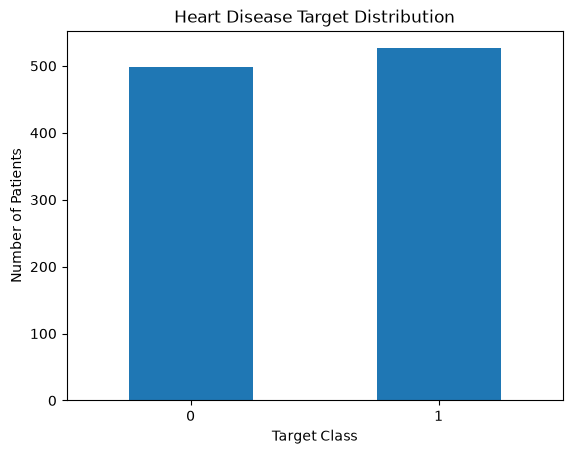

In [10]:
df["target"].value_counts().sort_index().plot(kind="bar")

plt.title("Heart Disease Target Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

# SIT307 11.1HD – Machine Learning Research

## Selected Paper
**An efficient stacking-based ensemble technique for early heart attack prediction**

## Part 1 – Reproduction Study

### 1. Dataset Inspection

The original study uses a public heart disease dataset containing 1,025 records and 14 attributes, including the target. This notebook first verifies the downloaded dataset before reproducing the preprocessing and machine-learning experiments reported in the paper.

In [11]:
print("DATASET SHAPE")
print(df.shape)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nTARGET COUNTS")
print(df["target"].value_counts().sort_index())

print("\nTARGET PERCENTAGES")
print((df["target"].value_counts(normalize=True).sort_index() * 100).round(2))

DATASET SHAPE
(1025, 14)

COLUMN NAMES
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

MISSING VALUES
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

DUPLICATE ROWS
723

TARGET COUNTS
target
0    499
1    526
Name: count, dtype: int64

TARGET PERCENTAGES
target
0    48.68
1    51.32
Name: proportion, dtype: float64


### 2. Reproduction Assumptions and Preprocessing Decisions

- The downloaded Kaggle dataset contains 1,025 records and 14 columns.
- The dataset contains no missing values, so regression-based missing-value imputation is not required for this downloaded version.
- All categorical variables are already numerically encoded.
- The dataset contains 723 duplicate rows. These duplicates are retained during Part 1 to reproduce the published experiment as closely as possible. Their effect will be investigated separately in the critical analysis / proposed method.
- An 80/20 train-test split is used. This is consistent with the reported test-set accuracies, although the paper does not clearly specify the exact split percentage.
- A fixed random seed of 42 is used for reproducibility because the paper does not provide a random seed.
- Continuous numerical features are standardized using statistics learned only from the training set.

In [12]:
X = df.drop("target", axis=1)
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1025, 13)
y shape: (1025,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 820
Testing samples: 205

Training target distribution:
target
1    421
0    399
Name: count, dtype: int64

Testing target distribution:
target
1    105
0    100
Name: count, dtype: int64


In [14]:
continuous_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()

X_train_scaled[continuous_features] = scaler.fit_transform(
    X_train[continuous_features]
)

X_test_scaled[continuous_features] = scaler.transform(
    X_test[continuous_features]
)

print("Scaling completed successfully.")
X_train_scaled.head()

Scaling completed successfully.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
4,0.811626,0,0,0.314729,0.895791,1,1,-1.921155,0,0.696525,1,3,2
688,0.152247,0,0,3.767643,0.779115,1,0,-0.725362,1,2.475810,0,2,3
477,0.262144,1,2,-0.242193,-0.368191,0,0,0.027545,0,-0.574393,1,1,3
336,0.262144,1,2,0.983035,-2.371116,1,1,1.046184,0,-0.743849,2,1,3
960,-0.287339,0,2,0.203344,-1.009905,0,0,0.869030,0,-0.828577,1,0,2


In [15]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nMissing values after preprocessing:")
print("Train:", X_train_scaled.isnull().sum().sum())
print("Test:", X_test_scaled.isnull().sum().sum())

Training shape: (820, 13)
Testing shape: (205, 13)

Missing values after preprocessing:
Train: 0
Test: 0


### 3. Reproduction of Individual Machine Learning Models

The paper evaluates six individual classifiers: Logistic Regression, Decision Tree, Random Forest, Extreme Gradient Boosting, Naive Bayes, and K-Nearest Neighbours. Where exact classifier hyperparameters were not explicitly reported in the paper, standard library settings were used with a fixed random seed where applicable for reproducibility.

In [16]:
from sklearn.metrics import matthews_corrcoef

print("Additional metric imported.")

Additional metric imported.


In [17]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ),

    "Naive Bayes": GaussianNB(),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("Six models created successfully.")

for name in models:
    print("-", name)

Six models created successfully.
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- Naive Bayes
- KNN


In [18]:
individual_results = []
trained_models = {}

for name, model in models.items():

    print(f"Training: {name}")

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    mcc = matthews_corrcoef(y_test, y_pred)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    specificity = tn / (tn + fp)

    individual_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Specificity": specificity,
        "MCC": mcc,
        "AUC": auc
    })

    trained_models[name] = model

    print("Done.")
    print()

Training: Logistic Regression


Done.

Training: Decision Tree


Done.



Training: Random Forest


Done.

Training: XGBoost


Done.

Training: Naive Bayes
Done.

Training: KNN
Done.



In [19]:
results_df = pd.DataFrame(individual_results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,Specificity,MCC,AUC
0,XGBoost,1.0000,1.0000,1.0000,1.0000,1.00,1.0000,1.0000
1,Random Forest,1.0000,1.0000,1.0000,1.0000,1.00,1.0000,1.0000
2,Decision Tree,0.9854,1.0000,0.9714,0.9855,1.00,0.9712,0.9857
3,KNN,0.8537,0.8571,0.8571,0.8571,0.85,0.7071,0.9540
4,Naive Bayes,0.8293,0.8070,0.8762,0.8402,0.78,0.6602,0.9043
5,Logistic Regression,0.8146,0.7638,0.9238,0.8362,0.70,0.6422,0.9297


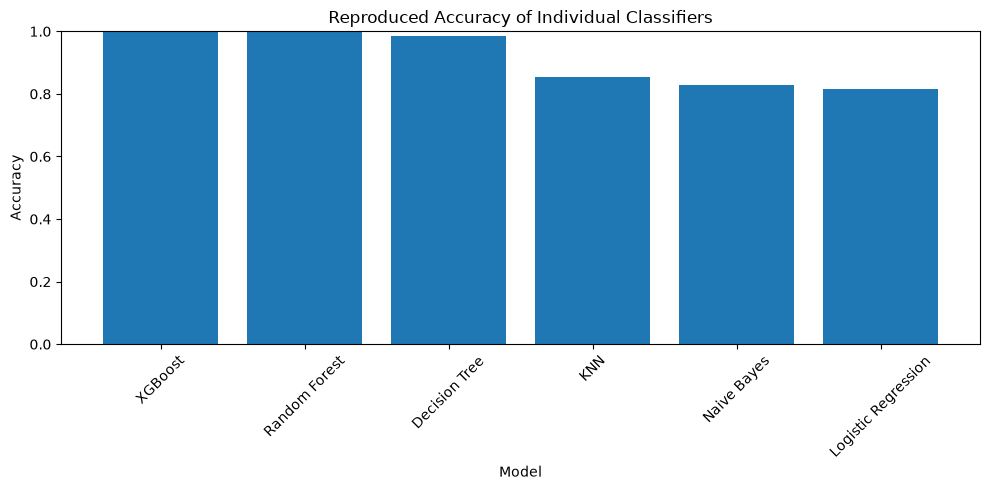

In [20]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Reproduced Accuracy of Individual Classifiers")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=45)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [21]:
results_df.to_csv(
    "results/individual_model_results.csv",
    index=False
)

print("Individual model results saved.")

Individual model results saved.


In [22]:
train_full = X_train.copy()
train_full["target"] = y_train

test_full = X_test.copy()
test_full["target"] = y_test

train_hashes = set(
    pd.util.hash_pandas_object(
        train_full.reset_index(drop=True),
        index=False
    )
)

test_hashes = pd.util.hash_pandas_object(
    test_full.reset_index(drop=True),
    index=False
)

overlap_count = test_hashes.isin(train_hashes).sum()

print("Training rows:", len(train_full))
print("Testing rows:", len(test_full))
print("Test rows also appearing in training:", overlap_count)
print(
    "Percentage of test set duplicated in training:",
    round(overlap_count / len(test_full) * 100, 2),
    "%"
)

Training rows: 820
Testing rows: 205
Test rows also appearing in training: 202
Percentage of test set duplicated in training: 98.54 %


In [23]:
published_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Naive Bayes",
        "KNN"
    ],
    "Published Accuracy": [
        0.8439,
        0.9268,
        0.9268,
        0.9073,
        0.8439,
        0.8585
    ]
})

comparison_df = pd.merge(
    results_df,
    published_results,
    on="Model"
)

comparison_df["Accuracy Difference"] = (
    comparison_df["Accuracy"]
    - comparison_df["Published Accuracy"]
)

comparison_df[
    [
        "Model",
        "Published Accuracy",
        "Accuracy",
        "Accuracy Difference"
    ]
].round(4)

,Model,Published Accuracy,Accuracy,Accuracy Difference
0,XGBoost,0.9073,1.0000,0.0927
1,Random Forest,0.9268,1.0000,0.0732
2,Decision Tree,0.9268,0.9854,0.0586
3,KNN,0.8585,0.8537,-0.0048
4,Naive Bayes,0.8439,0.8293,-0.0146
5,Logistic Regression,0.8439,0.8146,-0.0293


### 4. Initial Reproduction Observation

The reproduced tree-based models achieved substantially higher test accuracy than the values reported in the paper. In particular, Random Forest and XGBoost achieved 100% accuracy on the selected hold-out test set.

Dataset inspection identified 723 duplicate rows among the 1,025 records. Because the reproduction initially follows a conventional random train-test split while retaining the dataset as supplied by the paper's cited source, identical records may occur in both training and testing partitions. A separate overlap analysis is therefore performed to determine whether duplicate leakage could contribute to the unusually high reproduced performance.

This issue is retained and documented rather than silently removing duplicate observations because Part 1 aims to reproduce the published experimental setting as closely as possible. A stricter leakage-aware evaluation will be investigated separately.

### 5. Reproduction of the 5-Fold Stacking Ensemble

The selected paper proposes a 5-fold stacking ensemble in which predictions from multiple base classifiers are combined by a meta-classifier. The paper does not clearly specify every implementation detail of the meta-classifier and classifier hyperparameters. Therefore, this reproduction uses the six reported base model families and Logistic Regression as the meta-classifier, with 5-fold stratified cross-validation and a fixed random seed for reproducibility.

In [24]:
stacking_estimators = [
    (
        "lr",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    ),
    (
        "dt",
        DecisionTreeClassifier(
            random_state=42
        )
    ),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),
    (
        "xgb",
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        )
    ),
    (
        "nb",
        GaussianNB()
    ),
    (
        "knn",
        KNeighborsClassifier(
            n_neighbors=5
        )
    )
]

stacking_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    cv=stacking_cv,
    stack_method="predict_proba"
)

print("5-fold stacking model created successfully.")

5-fold stacking model created successfully.


In [25]:
stacking_model.fit(
    X_train_scaled,
    y_train
)

print("Stacking model trained successfully.")

Stacking model trained successfully.


In [26]:
stacking_predictions = stacking_model.predict(
    X_test_scaled
)

stacking_probabilities = stacking_model.predict_proba(
    X_test_scaled
)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [27]:
stack_accuracy = accuracy_score(
    y_test,
    stacking_predictions
)

stack_precision = precision_score(
    y_test,
    stacking_predictions
)

stack_recall = recall_score(
    y_test,
    stacking_predictions
)

stack_f1 = f1_score(
    y_test,
    stacking_predictions
)

stack_auc = roc_auc_score(
    y_test,
    stacking_probabilities
)

stack_mcc = matthews_corrcoef(
    y_test,
    stacking_predictions
)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    stacking_predictions
).ravel()

stack_specificity = tn / (tn + fp)

print("STACKING RESULTS")
print("Accuracy:", round(stack_accuracy, 4))
print("Precision:", round(stack_precision, 4))
print("Recall:", round(stack_recall, 4))
print("F1 Score:", round(stack_f1, 4))
print("Specificity:", round(stack_specificity, 4))
print("MCC:", round(stack_mcc, 4))
print("AUC:", round(stack_auc, 4))

STACKING RESULTS


Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Specificity: 1.0
MCC: 1.0
AUC: 1.0


In [28]:
print(
    classification_report(
        y_test,
        stacking_predictions,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ]
    )
)

                  precision    recall  f1-score   support

No Heart Disease       1.00      1.00      1.00       100
   Heart Disease       1.00      1.00      1.00       105

        accuracy                           1.00       205
       macro avg       1.00      1.00      1.00       205
    weighted avg       1.00      1.00      1.00       205



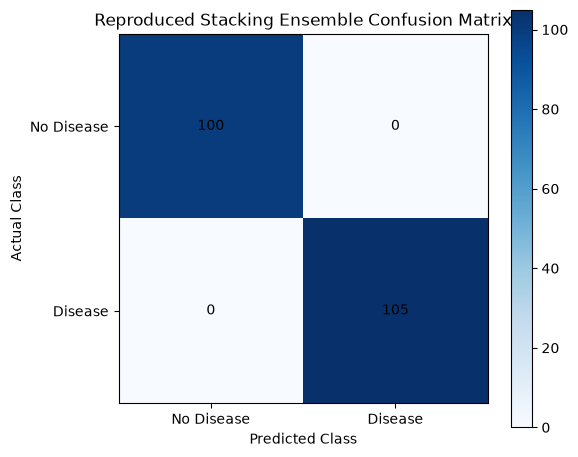

In [29]:
stacking_cm = confusion_matrix(
    y_test,
    stacking_predictions
)

plt.figure(figsize=(6, 5))

plt.imshow(
    stacking_cm,
    cmap="Blues"
)

plt.title("Reproduced Stacking Ensemble Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["No Disease", "Disease"]
)

plt.yticks(
    [0, 1],
    ["No Disease", "Disease"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            stacking_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

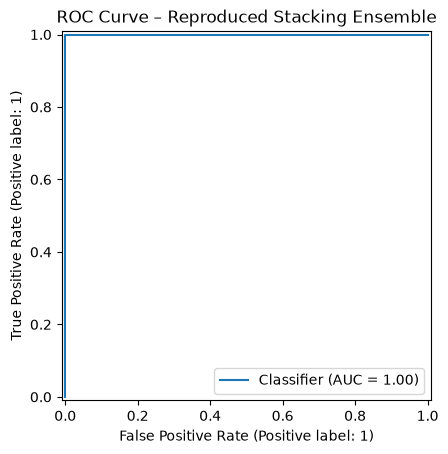

In [30]:
RocCurveDisplay.from_predictions(
    y_test,
    stacking_probabilities
)

plt.title("ROC Curve – Reproduced Stacking Ensemble")
plt.show()

In [31]:
stacking_result = pd.DataFrame([
    {
        "Model": "Stacking Ensemble",
        "Accuracy": stack_accuracy,
        "Precision": stack_precision,
        "Recall": stack_recall,
        "F1": stack_f1,
        "Specificity": stack_specificity,
        "MCC": stack_mcc,
        "AUC": stack_auc
    }
])

all_results_df = pd.concat(
    [
        results_df,
        stacking_result
    ],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

all_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,Specificity,MCC,AUC
0,XGBoost,1.0000,1.0000,1.0000,1.0000,1.00,1.0000,1.0000
1,Random Forest,1.0000,1.0000,1.0000,1.0000,1.00,1.0000,1.0000
2,Stacking Ensemble,1.0000,1.0000,1.0000,1.0000,1.00,1.0000,1.0000
3,Decision Tree,0.9854,1.0000,0.9714,0.9855,1.00,0.9712,0.9857
4,KNN,0.8537,0.8571,0.8571,0.8571,0.85,0.7071,0.9540
5,Naive Bayes,0.8293,0.8070,0.8762,0.8402,0.78,0.6602,0.9043
6,Logistic Regression,0.8146,0.7638,0.9238,0.8362,0.70,0.6422,0.9297


In [32]:
all_results_df.to_csv(
    "results/reproduction_all_models.csv",
    index=False
)

print("Complete reproduction results saved.")

Complete reproduction results saved.


In [33]:
published_full = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Stacking Ensemble"
    ],
    "Published Accuracy": [
        0.8439, 0.8439, 0.8585, 0.9268, 0.9268, 0.9073, 0.9853
    ],
    "Published Precision": [
        0.8196, 0.8250, 0.8648, 0.9702, 0.9130, 0.9174, 1.0000
    ],
    "Published Recall": [
        0.9090, 0.9000, 0.8727, 0.8909, 0.9545, 0.9090, 0.9727
    ],
    "Published F1": [
        0.8620, 0.8608, 0.8687, 0.9289, 0.9333, 0.9132, 0.9861
    ],
    "Published AUC": [
        0.9204, 0.9185, 0.9304, 0.9702, 0.9734, 0.9830, 0.9880
    ]
})

full_comparison = pd.merge(
    published_full,
    all_results_df[
        ["Model", "Accuracy", "Precision", "Recall", "F1", "AUC"]
    ],
    on="Model"
)

full_comparison["Accuracy Difference"] = (
    full_comparison["Accuracy"]
    - full_comparison["Published Accuracy"]
)

full_comparison.round(4)

,Model,Published Accuracy,Published Precision,Published Recall,Published F1,Published AUC,Accuracy,Precision,Recall,F1,AUC,Accuracy Difference
0,Logistic Regression,0.8439,0.8196,0.9090,0.8620,0.9204,0.8146,0.7638,0.9238,0.8362,0.9297,-0.0293
1,Naive Bayes,0.8439,0.8250,0.9000,0.8608,0.9185,0.8293,0.8070,0.8762,0.8402,0.9043,-0.0146
2,KNN,0.8585,0.8648,0.8727,0.8687,0.9304,0.8537,0.8571,0.8571,0.8571,0.9540,-0.0048
3,Decision Tree,0.9268,0.9702,0.8909,0.9289,0.9702,0.9854,1.0000,0.9714,0.9855,0.9857,0.0586
4,Random Forest,0.9268,0.9130,0.9545,0.9333,0.9734,1.0000,1.0000,1.0000,1.0000,1.0000,0.0732
5,XGBoost,0.9073,0.9174,0.9090,0.9132,0.9830,1.0000,1.0000,1.0000,1.0000,1.0000,0.0927
6,Stacking Ensemble,0.9853,1.0000,0.9727,0.9861,0.9880,1.0000,1.0000,1.0000,1.0000,1.0000,0.0147


In [34]:
full_comparison.to_csv(
    "results/published_vs_reproduced.csv",
    index=False
)

print("Published vs reproduced comparison saved.")

Published vs reproduced comparison saved.


### 6. Published vs Reproduced Results

The reproduction produced results close to the published study for KNN, Naive Bayes, and Logistic Regression, but substantially higher performance for the tree-based models and the stacking ensemble.

Random Forest, XGBoost, and the reproduced stacking ensemble achieved 100% test accuracy. Dataset inspection showed that 723 of the 1,025 rows are duplicates, and 202 of the 205 test observations (98.54%) also appeared exactly in the training set under the random hold-out split.

Therefore, the reproduced high performance should not be interpreted as evidence of perfect generalisation. The overlap analysis indicates that duplicate leakage is a major potential contributor to the inflated test performance. The original reproduction is retained as Part 1, while Part 2 investigates a stricter leakage-aware evaluation protocol.

In [35]:
df_unique = df.drop_duplicates().reset_index(drop=True)

print("Original rows:", len(df))
print("Duplicate rows removed:", len(df) - len(df_unique))
print("Unique rows remaining:", len(df_unique))

print("\nUnique target distribution:")
print(df_unique["target"].value_counts())

Original rows: 1025
Duplicate rows removed: 723
Unique rows remaining: 302

Unique target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [36]:
X_unique = df_unique.drop("target", axis=1)
y_unique = df_unique["target"]

X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    X_unique,
    y_unique,
    test_size=0.20,
    random_state=42,
    stratify=y_unique
)

print("Leakage-safe training samples:", len(X_train_u))
print("Leakage-safe testing samples:", len(X_test_u))

Leakage-safe training samples: 241
Leakage-safe testing samples: 61


In [37]:
X_train_u_scaled = X_train_u.copy()
X_test_u_scaled = X_test_u.copy()

unique_scaler = StandardScaler()

X_train_u_scaled[continuous_features] = unique_scaler.fit_transform(
    X_train_u[continuous_features]
)

X_test_u_scaled[continuous_features] = unique_scaler.transform(
    X_test_u[continuous_features]
)

print("Leakage-safe scaling completed.")

Leakage-safe scaling completed.


In [38]:
train_u_full = X_train_u.copy()
train_u_full["target"] = y_train_u

test_u_full = X_test_u.copy()
test_u_full["target"] = y_test_u

train_u_hashes = set(
    pd.util.hash_pandas_object(
        train_u_full.reset_index(drop=True),
        index=False
    )
)

test_u_hashes = pd.util.hash_pandas_object(
    test_u_full.reset_index(drop=True),
    index=False
)

unique_overlap = test_u_hashes.isin(train_u_hashes).sum()

print("Leakage-safe test rows also appearing in training:", unique_overlap)

Leakage-safe test rows also appearing in training:

 0


## Part 2 – Leakage-Aware Evaluation and Proposed Methodological Improvement

The original 1,025-row dataset contains 723 duplicate observations. Under the reproduction's random hold-out split, 202 of 205 test records (98.54%) also appeared exactly in the training set. This creates a substantial risk of duplicate leakage and inflated generalisation performance.

To address this limitation, the proposed evaluation first removes exact duplicate patient records before any train-test splitting. The resulting dataset contains 302 unique observations. A stratified 80/20 split is then applied, with preprocessing fitted only on the training partition. The same six classifiers and stacking ensemble are re-evaluated so that performance can be compared directly with the published results and Part 1 reproduction.

In [39]:
unique_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ),

    "Naive Bayes": GaussianNB(),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("Leakage-safe models created successfully.")

Leakage-safe models created successfully.


In [40]:
unique_results = []
unique_trained_models = {}

for name, model in unique_models.items():

    print(f"Training leakage-safe model: {name}")

    model.fit(
        X_train_u_scaled,
        y_train_u
    )

    y_pred_u = model.predict(
        X_test_u_scaled
    )

    y_prob_u = model.predict_proba(
        X_test_u_scaled
    )[:, 1]

    accuracy = accuracy_score(
        y_test_u,
        y_pred_u
    )

    precision = precision_score(
        y_test_u,
        y_pred_u
    )

    recall = recall_score(
        y_test_u,
        y_pred_u
    )

    f1 = f1_score(
        y_test_u,
        y_pred_u
    )

    auc = roc_auc_score(
        y_test_u,
        y_prob_u
    )

    mcc = matthews_corrcoef(
        y_test_u,
        y_pred_u
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test_u,
        y_pred_u
    ).ravel()

    specificity = tn / (tn + fp)

    unique_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Specificity": specificity,
        "MCC": mcc,
        "AUC": auc
    })

    unique_trained_models[name] = model

    print("Done.\n")

Training leakage-safe model: Logistic Regression
Done.

Training leakage-safe model: Decision Tree


Done.

Training leakage-safe model: Random Forest


Done.

Training leakage-safe model: XGBoost


Done.

Training leakage-safe model: Naive Bayes
Done.

Training leakage-safe model: KNN
Done.



In [41]:
unique_results_df = pd.DataFrame(
    unique_results
)

unique_results_df = unique_results_df.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

unique_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,Specificity,MCC,AUC
0,Logistic Regression,0.8033,0.8000,0.8485,0.8235,0.7500,0.6031,0.8701
1,Decision Tree,0.8033,0.8182,0.8182,0.8182,0.7857,0.6039,0.8019
2,KNN,0.7869,0.8125,0.7879,0.8000,0.7857,0.5724,0.8122
3,Naive Bayes,0.7869,0.8333,0.7576,0.7937,0.8214,0.5771,0.8842
4,Random Forest,0.7541,0.7647,0.7879,0.7761,0.7143,0.5038,0.8582
5,XGBoost,0.7213,0.7353,0.7576,0.7463,0.6786,0.4376,0.8323


In [42]:
unique_stacking_estimators = [
    (
        "lr",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    ),
    (
        "dt",
        DecisionTreeClassifier(
            random_state=42
        )
    ),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    ),
    (
        "xgb",
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        )
    ),
    (
        "nb",
        GaussianNB()
    ),
    (
        "knn",
        KNeighborsClassifier(
            n_neighbors=5
        )
    )
]

unique_stacking_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

unique_stacking_model = StackingClassifier(
    estimators=unique_stacking_estimators,
    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    cv=unique_stacking_cv,
    stack_method="predict_proba"
)

print("Leakage-safe stacking model created.")

Leakage-safe stacking model created.


In [43]:
unique_stacking_model.fit(
    X_train_u_scaled,
    y_train_u
)

unique_stack_pred = unique_stacking_model.predict(
    X_test_u_scaled
)

unique_stack_prob = unique_stacking_model.predict_proba(
    X_test_u_scaled
)[:, 1]

print("Leakage-safe stacking completed.")

Leakage-safe stacking completed.


In [44]:
u_stack_accuracy = accuracy_score(
    y_test_u,
    unique_stack_pred
)

u_stack_precision = precision_score(
    y_test_u,
    unique_stack_pred
)

u_stack_recall = recall_score(
    y_test_u,
    unique_stack_pred
)

u_stack_f1 = f1_score(
    y_test_u,
    unique_stack_pred
)

u_stack_auc = roc_auc_score(
    y_test_u,
    unique_stack_prob
)

u_stack_mcc = matthews_corrcoef(
    y_test_u,
    unique_stack_pred
)

tn, fp, fn, tp = confusion_matrix(
    y_test_u,
    unique_stack_pred
).ravel()

u_stack_specificity = tn / (tn + fp)

print("LEAKAGE-SAFE STACKING RESULTS")
print("Accuracy:", round(u_stack_accuracy, 4))
print("Precision:", round(u_stack_precision, 4))
print("Recall:", round(u_stack_recall, 4))
print("F1 Score:", round(u_stack_f1, 4))
print("Specificity:", round(u_stack_specificity, 4))
print("MCC:", round(u_stack_mcc, 4))
print("AUC:", round(u_stack_auc, 4))

LEAKAGE-SAFE STACKING RESULTS
Accuracy: 0.8197
Precision: 0.8438
Recall: 0.8182
F1 Score: 0.8308
Specificity: 0.8214
MCC: 0.6382
AUC: 0.8853


In [45]:
# Create leakage-safe stacking result row

unique_stacking_result = pd.DataFrame([
    {
        "Model": "Stacking Ensemble",
        "Accuracy": u_stack_accuracy,
        "Precision": u_stack_precision,
        "Recall": u_stack_recall,
        "F1": u_stack_f1,
        "Specificity": u_stack_specificity,
        "MCC": u_stack_mcc,
        "AUC": u_stack_auc
    }
])

# Combine six leakage-safe individual models + stacking

unique_all_results = pd.concat(
    [
        unique_results_df,
        unique_stacking_result
    ],
    ignore_index=True
)

unique_all_results = unique_all_results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("LEAKAGE-SAFE ALL MODELS")
display(unique_all_results.round(4))


# Create three-way comparison:
# Published vs Part 1 reproduction vs Leakage-safe Part 2

three_way_comparison = pd.merge(
    published_full[
        [
            "Model",
            "Published Accuracy",
            "Published Precision",
            "Published Recall",
            "Published F1",
            "Published AUC"
        ]
    ],
    all_results_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUC"
        ]
    ],
    on="Model"
)

three_way_comparison = pd.merge(
    three_way_comparison,
    unique_all_results[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUC"
        ]
    ],
    on="Model",
    suffixes=(
        "_Reproduction",
        "_LeakageSafe"
    )
)

print("\nTHREE-WAY COMPARISON")
display(three_way_comparison.round(4))

LEAKAGE-SAFE ALL MODELS


,Model,Accuracy,Precision,Recall,F1,Specificity,MCC,AUC
0,Stacking Ensemble,0.8197,0.8438,0.8182,0.8308,0.8214,0.6382,0.8853
1,Decision Tree,0.8033,0.8182,0.8182,0.8182,0.7857,0.6039,0.8019
2,Logistic Regression,0.8033,0.8000,0.8485,0.8235,0.7500,0.6031,0.8701
3,KNN,0.7869,0.8125,0.7879,0.8000,0.7857,0.5724,0.8122
4,Naive Bayes,0.7869,0.8333,0.7576,0.7937,0.8214,0.5771,0.8842
5,Random Forest,0.7541,0.7647,0.7879,0.7761,0.7143,0.5038,0.8582
6,XGBoost,0.7213,0.7353,0.7576,0.7463,0.6786,0.4376,0.8323



THREE-WAY COMPARISON


,Model,Published Accuracy,Published Precision,Published Recall,Published F1,Published AUC,Accuracy_Reproduction,Precision_Reproduction,Recall_Reproduction,F1_Reproduction,AUC_Reproduction,Accuracy_LeakageSafe,Precision_LeakageSafe,Recall_LeakageSafe,F1_LeakageSafe,AUC_LeakageSafe
0,Logistic Regression,0.8439,0.8196,0.9090,0.8620,0.9204,0.8146,0.7638,0.9238,0.8362,0.9297,0.8033,0.8000,0.8485,0.8235,0.8701
1,Naive Bayes,0.8439,0.8250,0.9000,0.8608,0.9185,0.8293,0.8070,0.8762,0.8402,0.9043,0.7869,0.8333,0.7576,0.7937,0.8842
2,KNN,0.8585,0.8648,0.8727,0.8687,0.9304,0.8537,0.8571,0.8571,0.8571,0.9540,0.7869,0.8125,0.7879,0.8000,0.8122
3,Decision Tree,0.9268,0.9702,0.8909,0.9289,0.9702,0.9854,1.0000,0.9714,0.9855,0.9857,0.8033,0.8182,0.8182,0.8182,0.8019
4,Random Forest,0.9268,0.9130,0.9545,0.9333,0.9734,1.0000,1.0000,1.0000,1.0000,1.0000,0.7541,0.7647,0.7879,0.7761,0.8582
5,XGBoost,0.9073,0.9174,0.9090,0.9132,0.9830,1.0000,1.0000,1.0000,1.0000,1.0000,0.7213,0.7353,0.7576,0.7463,0.8323
6,Stacking Ensemble,0.9853,1.0000,0.9727,0.9861,0.9880,1.0000,1.0000,1.0000,1.0000,1.0000,0.8197,0.8438,0.8182,0.8308,0.8853


### 7. Robust Leakage-Aware Evaluation Using Repeated Cross-Validation

A single hold-out split on the 302 unique records may be sensitive to which observations happen to enter the test set. Therefore, the leakage-aware methodology is further evaluated using repeated stratified cross-validation.

All preprocessing is performed inside the cross-validation pipeline so that scaling parameters are learned only from the training portion of each fold. Five-fold stratified cross-validation is repeated five times, producing 25 independent evaluation folds. Accuracy, precision, recall, F1-score, and ROC-AUC are reported as mean ± standard deviation.

In [46]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [47]:
cv_preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuous",
            StandardScaler(),
            continuous_features
        )
    ],
    remainder="passthrough"
)

print("Cross-validation preprocessor created.")

Cross-validation preprocessor created.


In [48]:
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

print("Repeated 5-fold CV created: 25 evaluation folds.")

Repeated 5-fold CV created: 25 evaluation folds.


In [49]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "auc": "roc_auc"
}

In [50]:
cv_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ),

    "Naive Bayes": GaussianNB(),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

repeated_cv_results = []

for name, model in cv_models.items():

    print("Evaluating:", name)

    pipeline = Pipeline([
        ("preprocessing", cv_preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_unique,
        y_unique,
        cv=repeated_cv,
        scoring=scoring,
        n_jobs=-1
    )

    repeated_cv_results.append({
        "Model": name,

        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),

        "Precision Mean": scores["test_precision"].mean(),
        "Precision SD": scores["test_precision"].std(),

        "Recall Mean": scores["test_recall"].mean(),
        "Recall SD": scores["test_recall"].std(),

        "F1 Mean": scores["test_f1"].mean(),
        "F1 SD": scores["test_f1"].std(),

        "AUC Mean": scores["test_auc"].mean(),
        "AUC SD": scores["test_auc"].std()
    })

print("Six-model repeated CV completed.")

Evaluating: Logistic Regression


Evaluating: Decision Tree


Evaluating: Random Forest


Evaluating: XGBoost


Evaluating: Naive Bayes


Evaluating: KNN


Six-model repeated CV completed.


In [51]:
repeated_cv_df = pd.DataFrame(
    repeated_cv_results
)

repeated_cv_df = repeated_cv_df.sort_values(
    "Accuracy Mean",
    ascending=False
).reset_index(drop=True)

repeated_cv_df.round(4)

,Model,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,F1 Mean,F1 SD,AUC Mean,AUC SD
0,Logistic Regression,0.8278,0.0264,0.8170,0.0453,0.8877,0.0639,0.8480,0.0240,0.9032,0.0255
1,Random Forest,0.8152,0.0284,0.8160,0.0472,0.8597,0.0577,0.8346,0.0252,0.9012,0.0259
2,Naive Bayes,0.8151,0.0383,0.8224,0.0450,0.8464,0.0704,0.8317,0.0383,0.8962,0.0330
3,KNN,0.8079,0.0332,0.7901,0.0327,0.8828,0.0586,0.8325,0.0318,0.8658,0.0378
4,XGBoost,0.8046,0.0515,0.8121,0.0493,0.8365,0.0802,0.8217,0.0519,0.8801,0.0316
5,Decision Tree,0.7470,0.0490,0.7645,0.0532,0.7769,0.0719,0.7685,0.0477,0.7442,0.0490


In [52]:
def make_base_pipeline(model):

    return Pipeline([
        (
            "preprocessing",
            ColumnTransformer(
                transformers=[
                    (
                        "continuous",
                        StandardScaler(),
                        continuous_features
                    )
                ],
                remainder="passthrough"
            )
        ),
        ("model", model)
    ])

In [53]:
cv_stacking_estimators = [
    (
        "lr",
        make_base_pipeline(
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ),

    (
        "dt",
        make_base_pipeline(
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ),

    (
        "rf",
        make_base_pipeline(
            RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )
        )
    ),

    (
        "xgb",
        make_base_pipeline(
            XGBClassifier(
                random_state=42,
                eval_metric="logloss"
            )
        )
    ),

    (
        "nb",
        make_base_pipeline(
            GaussianNB()
        )
    ),

    (
        "knn",
        make_base_pipeline(
            KNeighborsClassifier(
                n_neighbors=5
            )
        )
    )
]

In [54]:
cv_stacking_model = StackingClassifier(
    estimators=cv_stacking_estimators,

    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),

    stack_method="predict_proba"
)

print("Leakage-safe repeated-CV stacking model created.")

Leakage-safe repeated-CV stacking model created.


In [55]:
print("Evaluating Stacking Ensemble...")

stack_cv_scores = cross_validate(
    cv_stacking_model,
    X_unique,
    y_unique,
    cv=repeated_cv,
    scoring=scoring,
    n_jobs=-1
)

stack_cv_result = {
    "Model": "Stacking Ensemble",

    "Accuracy Mean": stack_cv_scores["test_accuracy"].mean(),
    "Accuracy SD": stack_cv_scores["test_accuracy"].std(),

    "Precision Mean": stack_cv_scores["test_precision"].mean(),
    "Precision SD": stack_cv_scores["test_precision"].std(),

    "Recall Mean": stack_cv_scores["test_recall"].mean(),
    "Recall SD": stack_cv_scores["test_recall"].std(),

    "F1 Mean": stack_cv_scores["test_f1"].mean(),
    "F1 SD": stack_cv_scores["test_f1"].std(),

    "AUC Mean": stack_cv_scores["test_auc"].mean(),
    "AUC SD": stack_cv_scores["test_auc"].std()
}

print("Stacking repeated CV completed.")

Evaluating Stacking Ensemble...


Stacking repeated CV completed.


In [56]:
repeated_cv_final = pd.concat(
    [
        repeated_cv_df,
        pd.DataFrame([stack_cv_result])
    ],
    ignore_index=True
)

repeated_cv_final = repeated_cv_final.sort_values(
    "Accuracy Mean",
    ascending=False
).reset_index(drop=True)

repeated_cv_final.round(4)

,Model,Accuracy Mean,Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,F1 Mean,F1 SD,AUC Mean,AUC SD
0,Stacking Ensemble,0.8298,0.0346,0.8231,0.0454,0.8805,0.0654,0.8483,0.0326,0.9039,0.0291
1,Logistic Regression,0.8278,0.0264,0.8170,0.0453,0.8877,0.0639,0.8480,0.0240,0.9032,0.0255
2,Random Forest,0.8152,0.0284,0.8160,0.0472,0.8597,0.0577,0.8346,0.0252,0.9012,0.0259
3,Naive Bayes,0.8151,0.0383,0.8224,0.0450,0.8464,0.0704,0.8317,0.0383,0.8962,0.0330
4,KNN,0.8079,0.0332,0.7901,0.0327,0.8828,0.0586,0.8325,0.0318,0.8658,0.0378
5,XGBoost,0.8046,0.0515,0.8121,0.0493,0.8365,0.0802,0.8217,0.0519,0.8801,0.0316
6,Decision Tree,0.7470,0.0490,0.7645,0.0532,0.7769,0.0719,0.7685,0.0477,0.7442,0.0490


In [57]:
repeated_cv_final.to_csv(
    "results/repeated_cv_leakage_safe.csv",
    index=False
)

print("Repeated-CV leakage-safe results saved.")

Repeated-CV leakage-safe results saved.


In [58]:
final_summary = pd.DataFrame({
    "Evaluation": [
        "Published Paper",
        "Part 1 Random-Split Reproduction",
        "Part 2 Leakage-Safe Holdout",
        "Part 2 Leakage-Safe Repeated CV"
    ],
    "Stacking Accuracy": [
        0.9853,
        stack_accuracy,
        u_stack_accuracy,
        stack_cv_result["Accuracy Mean"]
    ],
    "Stacking F1": [
        0.9861,
        stack_f1,
        u_stack_f1,
        stack_cv_result["F1 Mean"]
    ],
    "Stacking AUC": [
        0.9880,
        stack_auc,
        u_stack_auc,
        stack_cv_result["AUC Mean"]
    ]
})

final_summary.round(4)

,Evaluation,Stacking Accuracy,Stacking F1,Stacking AUC
0,Published Paper,0.9853,0.9861,0.9880
1,Part 1 Random-Split Reproduction,1.0000,1.0000,1.0000
2,Part 2 Leakage-Safe Holdout,0.8197,0.8308,0.8853
3,Part 2 Leakage-Safe Repeated CV,0.8298,0.8483,0.9039


In [59]:
published_acc = 0.9853
reproduction_acc = stack_accuracy
leakage_safe_cv_acc = stack_cv_result["Accuracy Mean"]

print(
    "Published → Leakage-safe CV accuracy change:",
    round((leakage_safe_cv_acc - published_acc) * 100, 2),
    "percentage points"
)

print(
    "Reproduction → Leakage-safe CV accuracy change:",
    round((leakage_safe_cv_acc - reproduction_acc) * 100, 2),
    "percentage points"
)

print(
    "Stacking advantage over Logistic Regression:",
    round(
        (
            stack_cv_result["Accuracy Mean"]
            - repeated_cv_df.loc[
                repeated_cv_df["Model"] == "Logistic Regression",
                "Accuracy Mean"
            ].iloc[0]
        ) * 100,
        2
    ),
    "percentage points"
)

Published → Leakage-safe CV accuracy change: -15.55 percentage points
Reproduction → Leakage-safe CV accuracy change: -17.02 percentage points
Stacking advantage over Logistic Regression: 0.2 percentage points


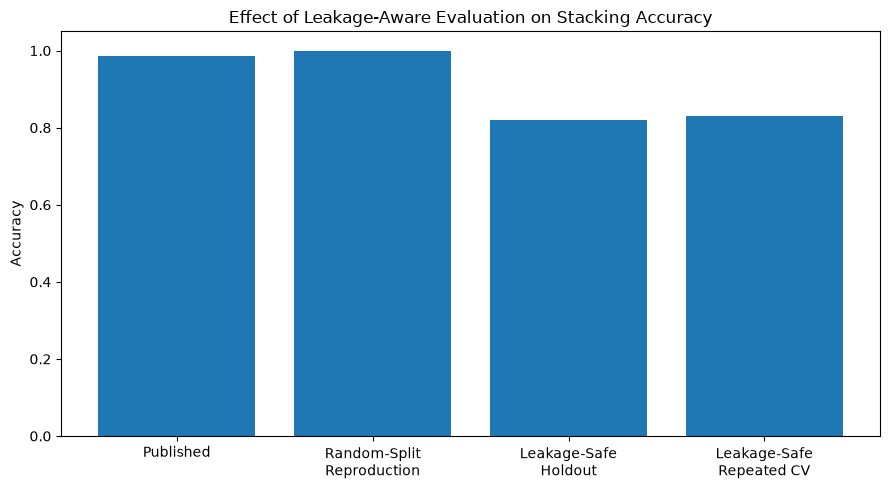

In [60]:
comparison_plot = pd.DataFrame({
    "Evaluation": [
        "Published",
        "Random-Split\nReproduction",
        "Leakage-Safe\nHoldout",
        "Leakage-Safe\nRepeated CV"
    ],
    "Stacking Accuracy": [
        0.9853,
        stack_accuracy,
        u_stack_accuracy,
        stack_cv_result["Accuracy Mean"]
    ]
})

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_plot["Evaluation"],
    comparison_plot["Stacking Accuracy"]
)

plt.title(
    "Effect of Leakage-Aware Evaluation on Stacking Accuracy"
)

plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    "figures/final_stacking_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8. Interpretation of the Proposed Leakage-Aware Methodology

The repeated leakage-aware evaluation confirms that the very high performance observed under the original random-split reproduction is not representative of performance on genuinely unseen unique patient records.

The published stacking ensemble reports 98.53% accuracy, while the random-split reproduction achieved 100%. However, 98.54% of the reproduction test observations had exact duplicates in the training partition.

After removing duplicate patient records, preventing train-test overlap, fitting preprocessing only within training folds, and evaluating the models across 25 repeated stratified folds, the stacking ensemble achieved a mean accuracy of approximately 82.98%, with an accuracy standard deviation of approximately 3.46%.

The leakage-aware stacking model remained the highest-ranked model by mean accuracy, but its advantage over Logistic Regression was very small. Logistic Regression achieved approximately 82.78% mean accuracy, indicating that much of the apparent advantage of the more complex ensemble disappears when duplicate leakage is controlled.

These results suggest that leakage-aware validation provides a more conservative and defensible estimate of generalisation performance than a conventional random split on the duplicated dataset.

In [61]:
final_summary.to_csv(
    "results/final_stacking_summary.csv",
    index=False
)

print("Final summary saved.")

Final summary saved.


### 9. Technical Conclusion

The reproduction initially produced extremely high performance, including 100% accuracy for Random Forest, XGBoost, and the stacking ensemble. However, dataset auditing revealed 723 duplicate observations, and 98.54% of the random-split test records were also present in the training partition.

The proposed leakage-aware methodology removed exact duplicate records, ensured zero train-test overlap, applied preprocessing within training folds, and used repeated stratified cross-validation across 25 evaluation folds. Under this stricter protocol, the stacking ensemble achieved approximately 82.98% mean accuracy, 84.83% mean F1-score, and 90.39% mean AUC.

The stacking ensemble remained the highest-ranked model by mean accuracy, but its advantage over Logistic Regression was very small. This suggests that the extremely high performance reported under the duplicated-data evaluation should be interpreted cautiously when estimating generalisation to genuinely unseen patient records.

### GenAI Acknowledgement

Generative AI tools, including ChatGPT, were used to support planning, explanation of machine-learning concepts, debugging guidance, and review of the experimental workflow. Before submission, I reviewed, tested, and understood the code and analysis included in this notebook and verified the reported outputs against the executed experiments.